# Mobile Wallet Fraud Detection

## 1. Business Understanding

### Problem Statement

The increasing adoption of mobile payment services has created new opportunities for financial fraud. Mobile wallet providers need reliable systems to identify suspicious transactions and minimize financial losses while maintaining a smooth experience for legitimate customers.

This project aims to develop a Machine Learning classification system that identifies potentially fraudulent mobile money transactions.

### Business Objective

Build a predictive model that can:

- Identify fraudulent transactions before financial losses occur.
- Minimize missed fraudulent transactions.
- Reduce false alarms that affect legitimate customers.
- Support better fraud investigation and transaction monitoring.

### Machine Learning Objective

Develop a binary classification model to predict whether a transaction is fraudulent.

**Target Variable:** `isFraud`

- `0`: Legitimate transaction.
- `1`: Fraudulent transaction.

### Business Success Metrics

Because fraud is a rare event, accuracy alone is insufficient.

We will prioritize:

- **Recall:** Ability to identify fraudulent transactions.
- **Precision:** Reliability of fraud alerts.
- **F1-score:** Balance between precision and recall.
- **PR-AUC:** Overall ranking performance for the minority class.

### Dataset

PaySim Mobile Money Simulation Dataset.

Source: https://www.kaggle.com/datasets/ealaxi/paysim1

## 2. Import Libraries & Configuration

This section imports the required libraries for data manipulation, visualization, statistical analysis, preprocessing, and Machine Learning.

We also configure reproducibility by defining a fixed random seed.

In [49]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Machine Learning utilities
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    RobustScaler,
    FunctionTransformer
)
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Configuration
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Data Loading

Load the original PaySim dataset into a Pandas DataFrame.

We will preserve the original dataset at this stage.
No rows or columns will be removed before completing data validation.

In [2]:
df = pd.read_csv(
    "../data/detection.csv"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [3]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 6,362,620
Number of columns: 11


In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,"6,362,620.0000",NaN,NaN,NaN,243.3972,142.3320,1.0000,156.0000,239.0000,335.0000,743.0000
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,"6,362,620.0000",NaN,NaN,NaN,"179,861.9035","603,858.2315",0.0000,"13,389.5700","74,871.9400","208,721.4775","92,445,516.6400"
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,"6,362,620.0000",NaN,NaN,NaN,"833,883.1041","2,888,242.6730",0.0000,0.0000,"14,208.0000","107,315.1750","59,585,040.3700"
newbalanceOrig,"6,362,620.0000",NaN,NaN,NaN,"855,113.6686","2,924,048.5030",0.0000,0.0000,0.0000,"144,258.4100","49,585,040.3700"
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,"6,362,620.0000",NaN,NaN,NaN,"1,100,701.6665","3,399,180.1130",0.0000,0.0000,"132,705.6650","943,036.7075","356,015,889.3500"
newbalanceDest,"6,362,620.0000",NaN,NaN,NaN,"1,224,996.3982","3,674,128.9421",0.0000,0.0000,"214,661.4400","1,111,909.2500","356,179,278.9200"
isFraud,"6,362,620.0000",NaN,NaN,NaN,0.0013,0.0359,0.0000,0.0000,0.0000,0.0000,1.0000


In [6]:
EXPECTED_COLUMNS = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
    "isFlaggedFraud"
]

assert not df.empty, "Dataset is empty."

assert list(df.columns) == EXPECTED_COLUMNS, (
    "Dataset columns do not match the expected structure."
)

assert "isFraud" in df.columns, "Target column is missing."

print("Dataset structure validated successfully.")

Dataset structure validated successfully.


## 4. Data Quality Assessment

### 4.1 Missing Values

Check the number and percentage of missing values in each column.

Missing values can affect statistical analysis, preprocessing,
and model training.

In [7]:
df.isnull().sum(),


(step              0
 type              0
 amount            0
 nameOrig          0
 oldbalanceOrg     0
 newbalanceOrig    0
 nameDest          0
 oldbalanceDest    0
 newbalanceDest    0
 isFraud           0
 isFlaggedFraud    0
 dtype: int64,)

### 4.2 Duplicate Records

Identify completely duplicated transactions.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
print("Transaction types:")
print(df["type"].value_counts(dropna=False))

print("\nFraud target values:")
print(df["isFraud"].value_counts(dropna=False))

print("\nFlagged fraud values:")
print(df["isFlaggedFraud"].value_counts(dropna=False))

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Fraud target values:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Flagged fraud values:
isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns

# Negative values
negative_summary = (df[numeric_columns] < 0).sum()

print("Negative values per numerical column:")
print(negative_summary)

Negative values per numerical column:
step              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


### 5.1 Target Variable Distribution

The target variable `isFraud` indicates whether a transaction
is fraudulent or legitimate.

Understanding its distribution is essential because fraud
detection datasets usually contain significantly fewer
fraudulent transactions than legitimate ones.

This imbalance can make accuracy misleading.

In [11]:
target_counts = df["isFraud"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "Transaction_Count": target_counts,
    "Percentage": target_counts / len(df) * 100
})

target_summary.index = ["Legitimate", "Fraud"]

target_summary

,Transaction_Count,Percentage
Legitimate,6354407,99.8709
Fraud,8213,0.1291


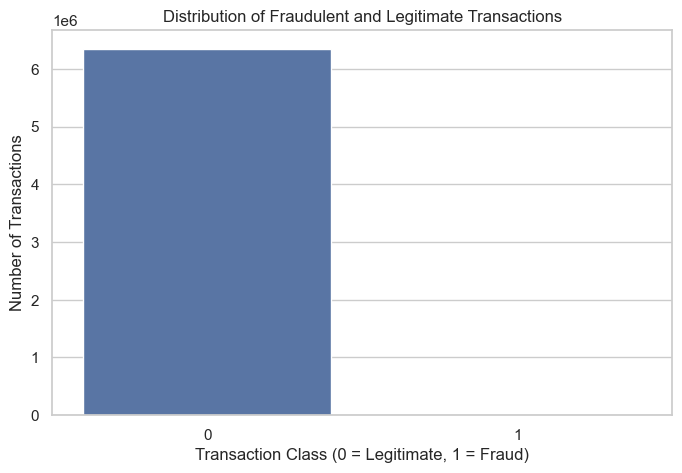

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="isFraud"
)

plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

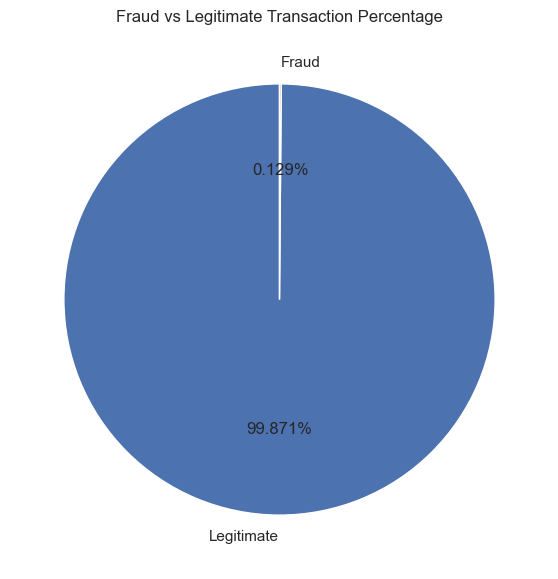

In [13]:
plt.figure(figsize=(7, 7))

plt.pie(
    target_counts,
    labels=["Legitimate", "Fraud"],
    autopct="%1.3f%%",
    startangle=90
)

plt.title("Fraud vs Legitimate Transaction Percentage")
plt.show()

### 5.2 Transaction Type Distribution

PaySim contains five transaction types:

- CASH_IN
- CASH_OUT
- DEBIT
- PAYMENT
- TRANSFER

We analyze their frequencies to understand the transaction
behavior represented in the dataset.

In [14]:
type_counts = df["type"].value_counts()

type_summary = pd.DataFrame({
    "Transaction_Count": type_counts,
    "Percentage": type_counts / len(df) * 100
})

type_summary

,Transaction_Count,Percentage
type,,
CASH_OUT,2237500,35.1663
PAYMENT,2151495,33.8146
CASH_IN,1399284,21.9923
TRANSFER,532909,8.3756
DEBIT,41432,0.6512


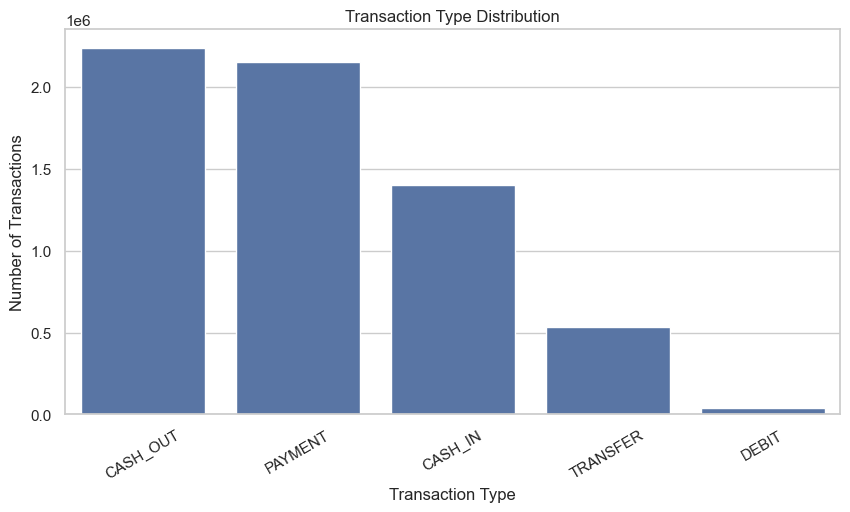

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="type",
    order=df["type"].value_counts().index
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.show()

### 5.3 Fraud Analysis Across Transaction Types

We compare fraudulent and legitimate transactions across
different transaction types.

Fraud Rate is calculated as:

Number of fraudulent transactions / Total transactions

This allows us to compare fraud risk across transaction types,
even when their transaction volumes differ.

In [16]:
fraud_by_type = df.groupby("type").agg(
    Total_Transactions=("isFraud", "size"),
    Fraud_Transactions=("isFraud", "sum")
)

fraud_by_type["Legitimate_Transactions"] = (
    fraud_by_type["Total_Transactions"]
    - fraud_by_type["Fraud_Transactions"]
)

fraud_by_type["Fraud_Rate_Percentage"] = (
    fraud_by_type["Fraud_Transactions"]
    / fraud_by_type["Total_Transactions"]
    * 100
)

fraud_by_type.sort_values(
    "Fraud_Rate_Percentage",
    ascending=False
)

,Total_Transactions,Fraud_Transactions,Legitimate_Transactions,Fraud_Rate_Percentage
type,,,,
TRANSFER,532909,4097,528812,0.7688
CASH_OUT,2237500,4116,2233384,0.1840
CASH_IN,1399284,0,1399284,0.0000
DEBIT,41432,0,41432,0.0000
PAYMENT,2151495,0,2151495,0.0000


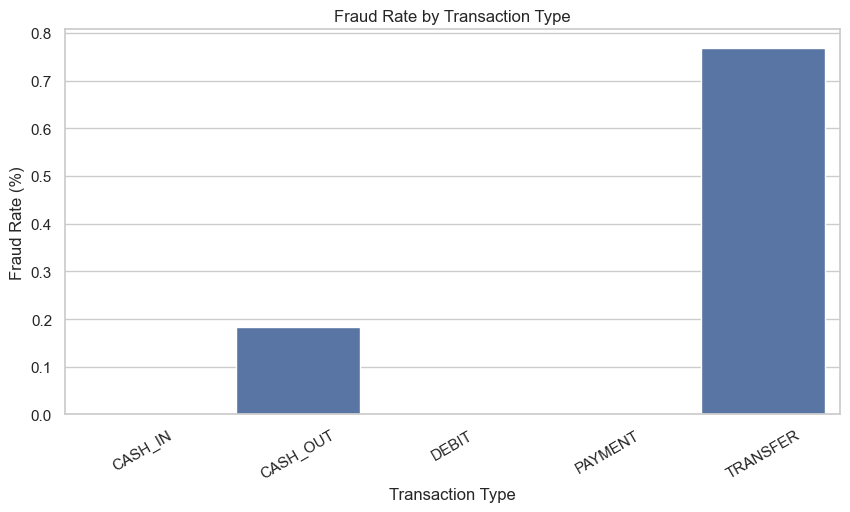

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=fraud_by_type.reset_index(),
    x="type",
    y="Fraud_Rate_Percentage"
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)

plt.show()

### 5.4 Transaction Amount Analysis

We investigate the distribution of transaction amounts
and compare fraudulent transactions with legitimate ones.

Financial transaction amounts often have right-skewed
distributions, meaning a small number of transactions
can have extremely large values.

We will use logarithmic transformations for visualization
where appropriate.

In [18]:
amount_summary = df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

amount_summary.index = ["Legitimate", "Fraud"]

amount_summary

,count,mean,median,std,min,max
Legitimate,6354407,"178,197.0417","74,684.7200","596,236.9813",0.0100,"92,445,516.6400"
Fraud,8213,"1,467,967.2991","441,423.4400","2,404,252.9472",0.0000,"10,000,000.0000"


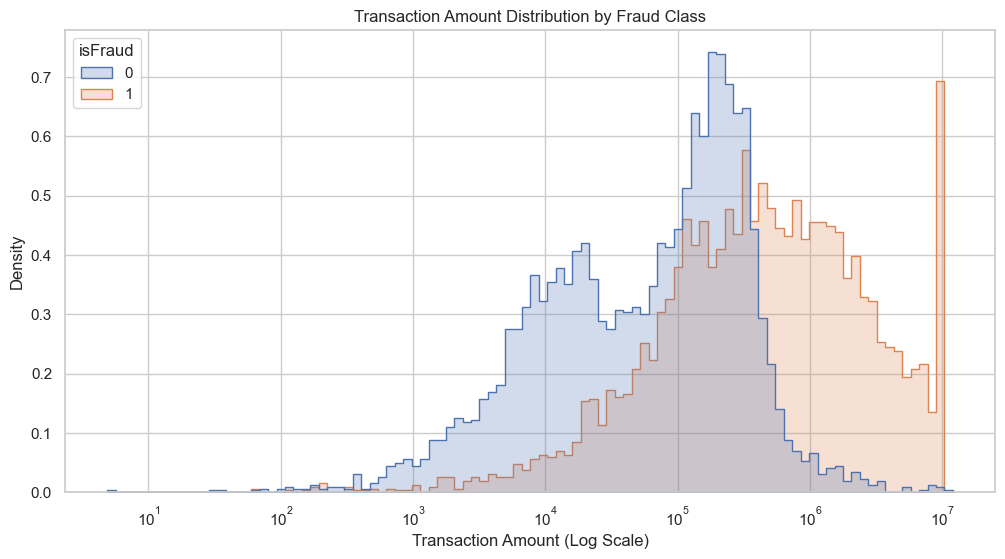

In [25]:
amount_sample = df.groupby(
    "isFraud",
    group_keys=False
).sample(
    n=min(5000, df["isFraud"].value_counts().min()),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=amount_sample,
    x="amount",
    hue="isFraud",
    bins=100,
    log_scale=(True, False),
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Amount Distribution by Fraud Class")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Density")

plt.show()

### 5.5 Account Balance Analysis

We analyze the account balances before and after transactions.

The analysis includes:

- oldbalanceOrg
- newbalanceOrig
- oldbalanceDest
- newbalanceDest

These variables may reveal differences in account behavior
between fraudulent and legitimate transactions.

Post-transaction balances are included for exploratory analysis
but will be excluded from the real-time model if unavailable
at prediction time.

In [22]:
balance_columns = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

balance_summary = df.groupby("isFraud")[balance_columns].agg(
    ["mean", "median"]
)

balance_summary

oldbalanceOrg              newbalanceOrig        oldbalanceDest  \
                  mean       median           mean median           mean   
isFraud                                                                    
0         832,828.7117  14,069.0000   855,970.2281 0.0000 1,101,420.8746   
1       1,649,667.6057 438,983.4500   192,392.6318 0.0000   544,249.6191   

                     newbalanceDest               
              median           mean       median  
isFraud                                           
0       133,311.8000 1,224,925.6846 214,881.7000  
1             0.0000 1,279,707.6171   4,676.4200

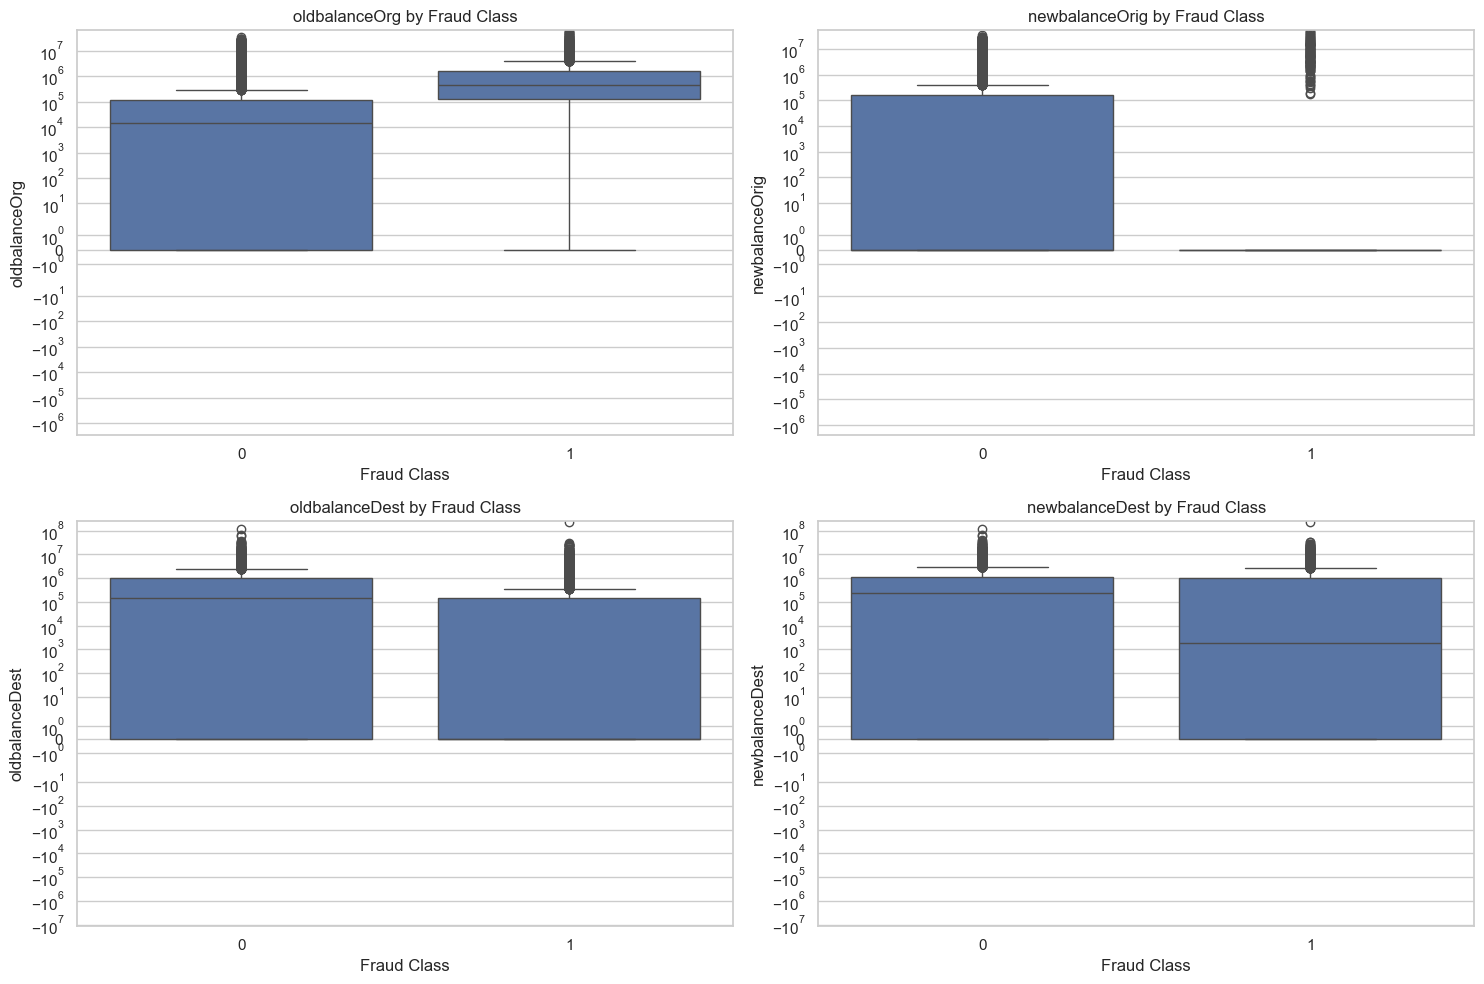

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, ax in zip(balance_columns, axes.flatten()):

    sns.boxplot(
        data=amount_sample,
        x="isFraud",
        y=column,
        ax=ax
    )

    ax.set_yscale("symlog")
    ax.set_title(f"{column} by Fraud Class")
    ax.set_xlabel("Fraud Class")

plt.tight_layout()
plt.show()

### 2.6 Correlation Analysis

Correlation analysis helps identify linear relationships
between numerical variables.

We use Pearson correlation to calculate the correlation matrix.

The target variable is included to explore its linear association
with individual numerical features.

However, correlation alone is not sufficient for feature selection,
especially in nonlinear classification problems.

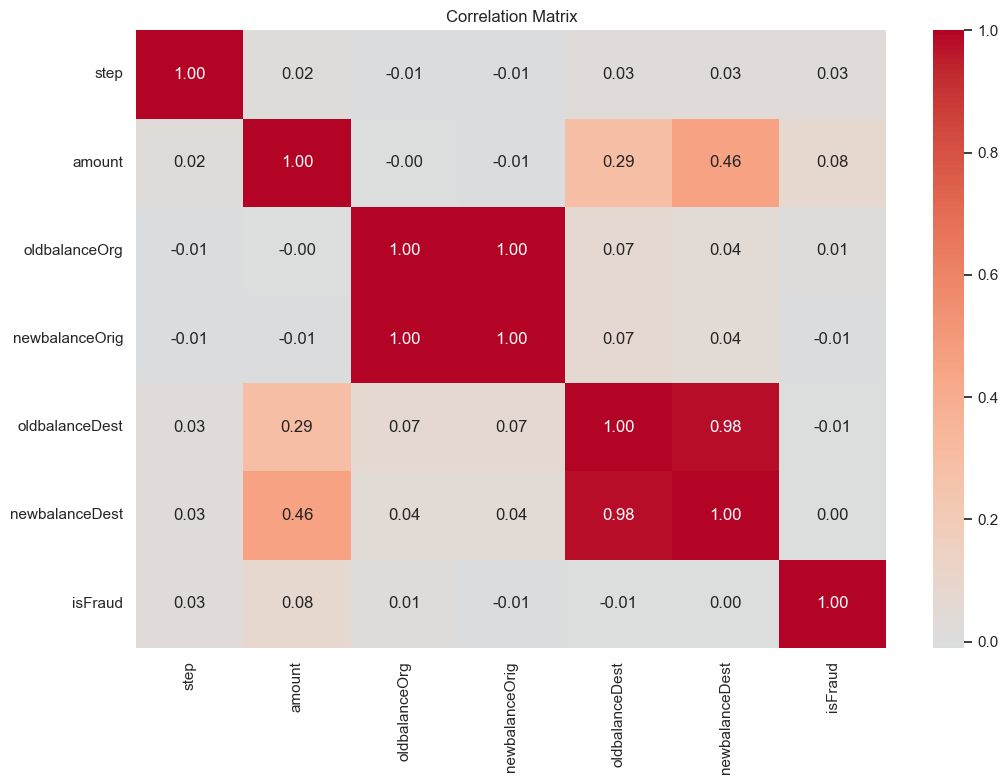

In [27]:
correlation_columns = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### 5.7 Temporal Fraud Analysis

The `step` variable represents time steps in the PaySim simulation.

We aggregate transactions by step to investigate:

- Total transaction volume.
- Number of fraudulent transactions.
- Fraud rate.

This analysis may reveal temporal patterns and changes
in fraud activity.

In [28]:
fraud_over_time = df.groupby("step").agg(
    total_transactions=("isFraud", "size"),
    fraud_transactions=("isFraud", "sum")
)

fraud_over_time["fraud_rate"] = (
    fraud_over_time["fraud_transactions"]
    / fraud_over_time["total_transactions"]
    * 100
)

fraud_over_time.head()

,total_transactions,fraud_transactions,fraud_rate
step,,,
1,2708,16,0.5908
2,1014,8,0.7890
3,552,4,0.7246
4,565,10,1.7699
5,665,6,0.9023


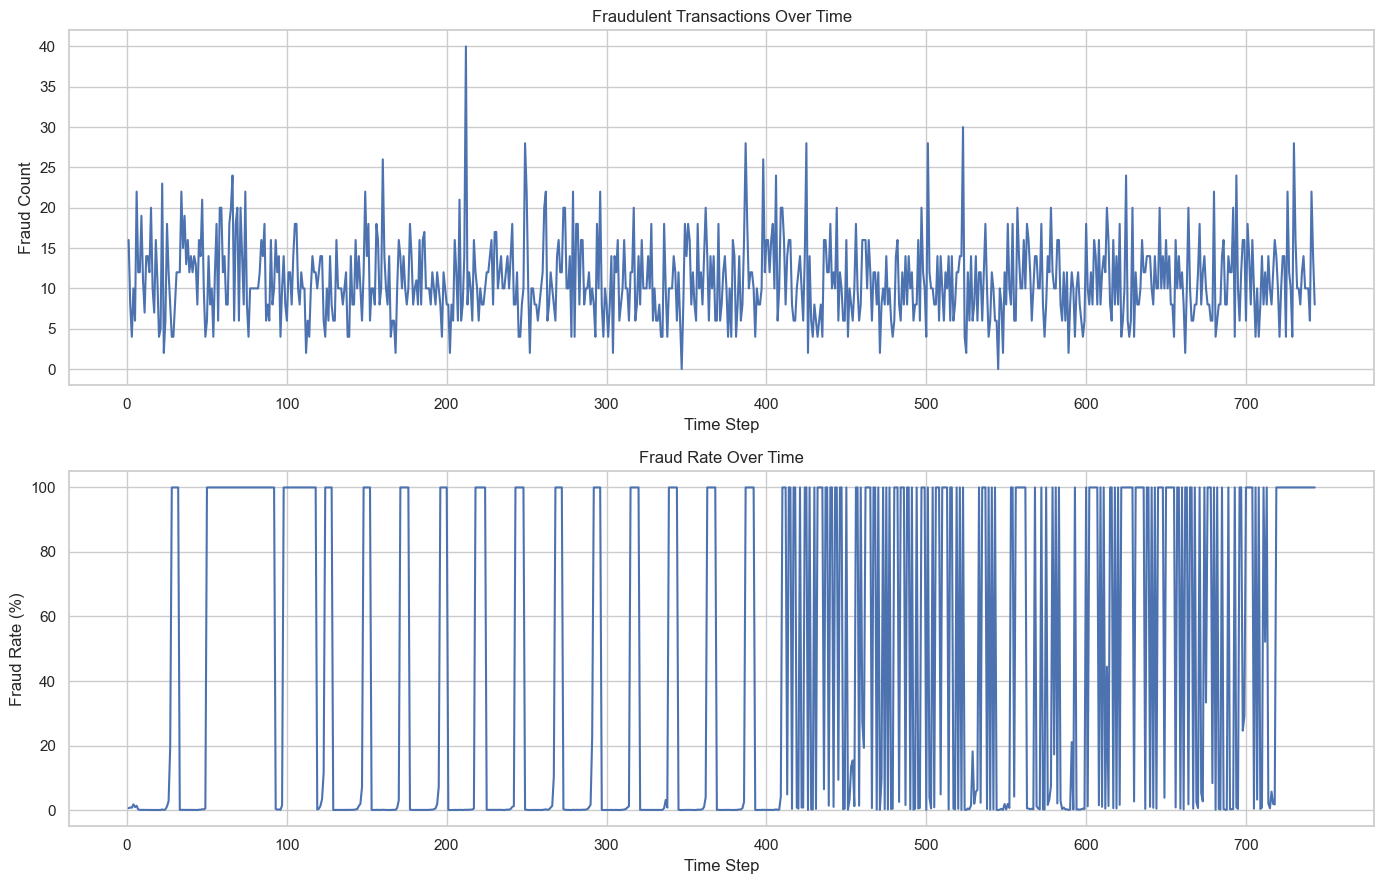

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

fraud_over_time["fraud_transactions"].plot(
    ax=axes[0]
)

axes[0].set_title("Fraudulent Transactions Over Time")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Fraud Count")

fraud_over_time["fraud_rate"].plot(
    ax=axes[1]
)

axes[1].set_title("Fraud Rate Over Time")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [30]:
quality_report = pd.DataFrame(index=df.columns)

quality_report["data_type"] = df.dtypes.astype(str)
quality_report["missing_count"] = df.isnull().sum()
quality_report["missing_percentage"] = (
    df.isnull().mean() * 100
)
quality_report["unique_values"] = df.nunique()
quality_report["duplicate_count"] = df.duplicated().sum()

quality_report

,data_type,missing_count,missing_percentage,unique_values,duplicate_count
step,int64,0,0.0000,743,0
type,str,0,0.0000,5,0
amount,float64,0,0.0000,5316900,0
nameOrig,str,0,0.0000,6353307,0
oldbalanceOrg,float64,0,0.0000,1845844,0
newbalanceOrig,float64,0,0.0000,2682586,0
nameDest,str,0,0.0000,2722362,0
oldbalanceDest,float64,0,0.0000,3614697,0
newbalanceDest,float64,0,0.0000,3555499,0
isFraud,int64,0,0.0000,2,0


In [31]:
df_clean = df.copy()

In [32]:
outlier_columns = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

outlier_results = []

for column in outlier_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    )

    outlier_results.append({
        "Feature": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_Percentage": outlier_mask.mean() * 100
    })

outlier_report = pd.DataFrame(outlier_results)

outlier_report

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,amount,"-279,608.2913","501,719.3387",338078,5.3135
1,oldbalanceOrg,"-160,972.7625","268,287.9375",1112507,17.4850
2,newbalanceOrig,"-216,387.6150","360,646.0250",1053391,16.5559
3,oldbalanceDest,"-1,414,555.0613","2,357,591.7687",786135,12.3555
4,newbalanceDest,"-1,667,863.8750","2,779,773.1250",738527,11.6073


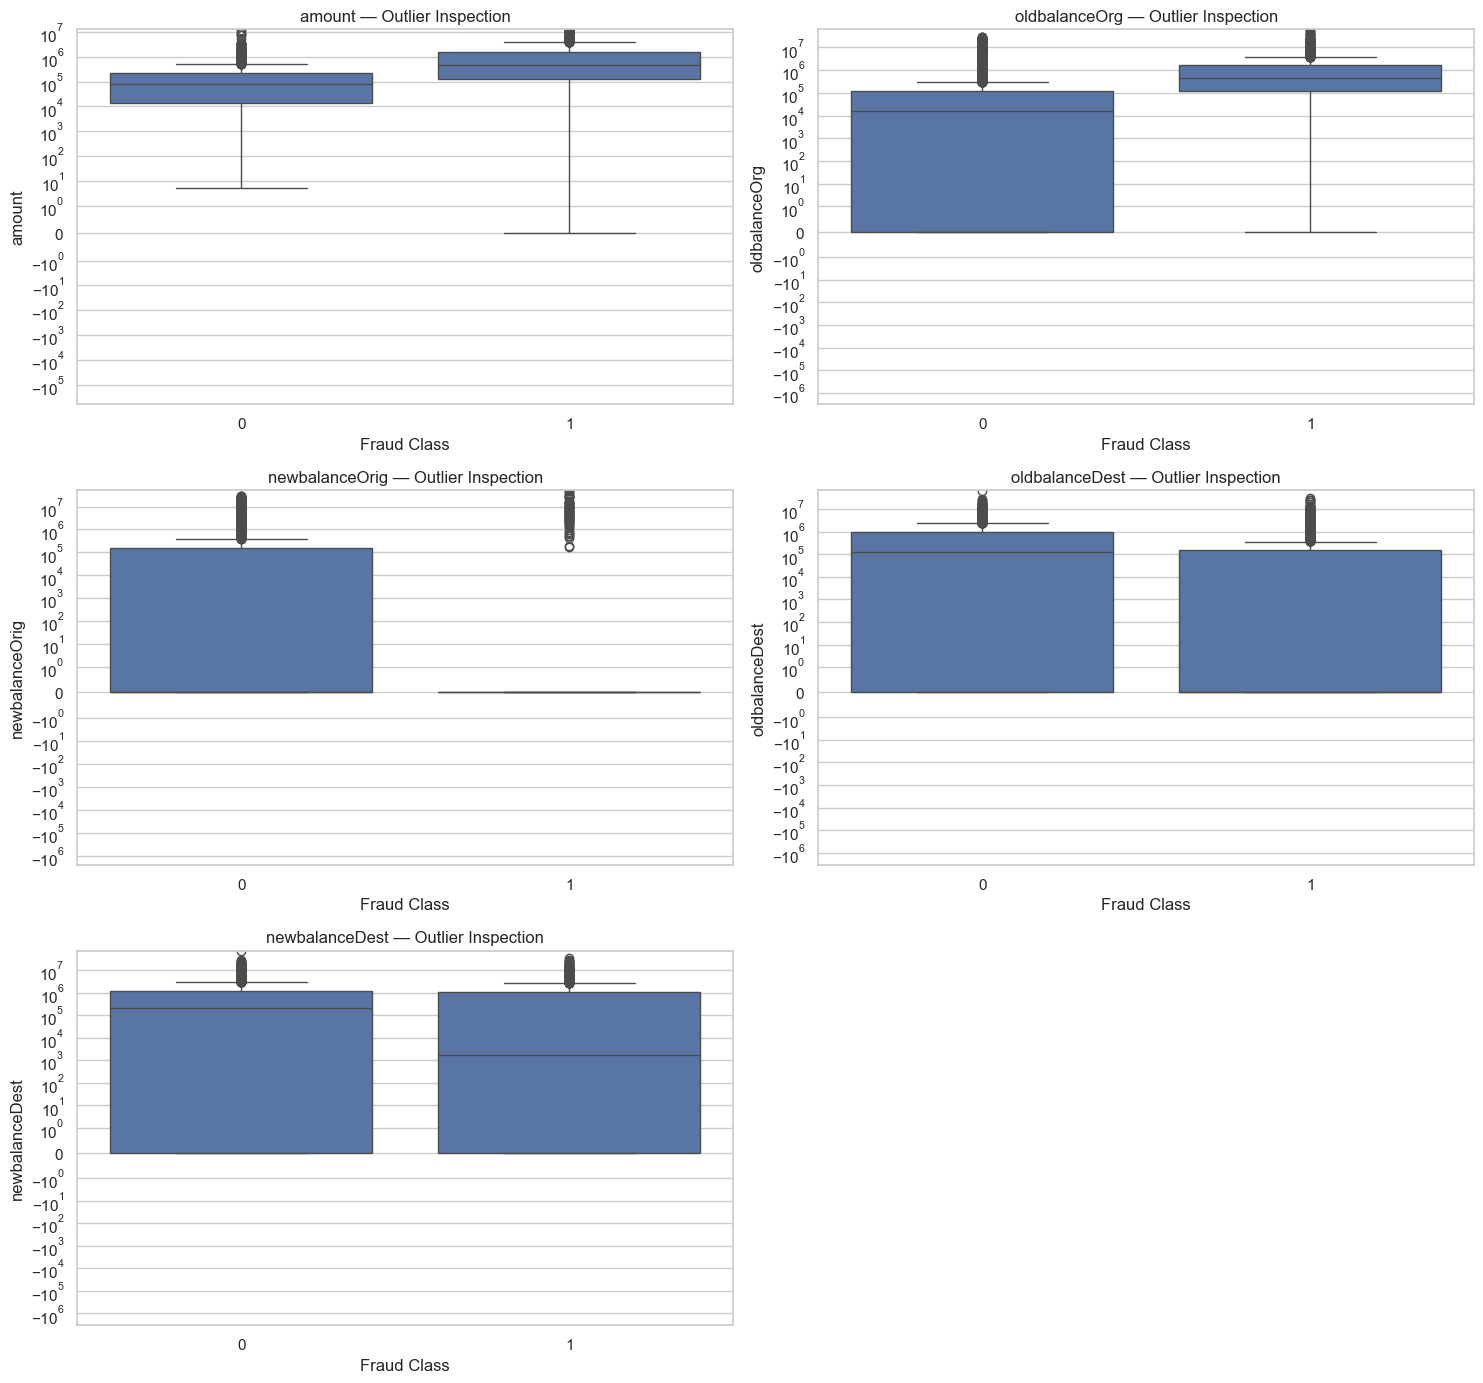

In [34]:
outlier_sample = df_clean.groupby(
    "isFraud",
    group_keys=False
).sample(
    n=min(3000, df_clean["isFraud"].value_counts().min()),
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for column, ax in zip(
    outlier_columns,
    axes.flatten()
):
    sns.boxplot(
        data=outlier_sample,
        x="isFraud",
        y=column,
        ax=ax
    )

    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(f"{column} — Outlier Inspection")
    ax.set_xlabel("Fraud Class")

axes[-1, -1].axis("off")

plt.tight_layout()
plt.show()

In [33]:
df_clean["type"] = df_clean["type"].astype("category")

df_clean["isFraud"] = df_clean["isFraud"].astype("uint8")

df_clean["isFlaggedFraud"] = (
    df_clean["isFlaggedFraud"].astype("uint8")
)

print(
    f"Optimized memory usage: "
    f"{df_clean.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)

Optimized memory usage: 533.75 MB


### 5.8 Initial Feature Selection

We define an initial feature set based on information
available before transaction execution.

The target variable is `isFraud`.

Account identifiers and post-transaction information
are excluded from the initial model.

In [35]:
NUMERIC_FEATURES = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

CATEGORICAL_FEATURES = [
    "type"
]

print("Numerical features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

Numerical features: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest']
Categorical features: ['type']


In [37]:
encoder_demo = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_demo = encoder_demo.fit_transform(
    df_clean[["type"]].head(10)
)

encoded_columns = encoder_demo.get_feature_names_out(
    ["type"]
)

encoded_demo_df = pd.DataFrame(
    encoded_demo,
    columns=encoded_columns
)

encoded_demo_df

,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,0.0000,0.0000,1.0000,0.0000
1,0.0000,0.0000,1.0000,0.0000
2,0.0000,0.0000,0.0000,1.0000
3,1.0000,0.0000,0.0000,0.0000
4,0.0000,0.0000,1.0000,0.0000
5,0.0000,0.0000,1.0000,0.0000
6,0.0000,0.0000,1.0000,0.0000
7,0.0000,0.0000,1.0000,0.0000
8,0.0000,0.0000,1.0000,0.0000
9,0.0000,1.0000,0.0000,0.0000


In [39]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int64   
 1   type            category
 2   amount          float64 
 3   nameOrig        str     
 4   oldbalanceOrg   float64 
 5   newbalanceOrig  float64 
 6   nameDest        str     
 7   oldbalanceDest  float64 
 8   newbalanceDest  float64 
 9   isFraud         uint8   
 10  isFlaggedFraud  uint8   
dtypes: category(1), float64(5), int64(1), str(2), uint8(2)
memory usage: 533.8 MB


In [41]:
scaler_demo = StandardScaler()

scaled_demo = scaler_demo.fit_transform(
    df_clean[NUMERIC_FEATURES].sample(
        n=10000,
        random_state=RANDOM_STATE
    )
)

scaled_demo_df = pd.DataFrame(
    scaled_demo,
    columns=NUMERIC_FEATURES
)

scaled_demo_df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"10,000.0000",-0.0000,1.0001,-1.7149,-0.6210,0.0354,0.7146,3.3382
amount,"10,000.0000",-0.0000,1.0001,-0.3726,-0.3439,-0.2134,0.0689,36.6750
oldbalanceOrg,"10,000.0000",0.0000,1.0001,-0.2932,-0.2932,-0.2887,-0.2580,10.5905
oldbalanceDest,"10,000.0000",-0.0000,1.0001,-0.3742,-0.3742,-0.3269,-0.0404,32.1374


In [42]:
robust_scaler_demo = RobustScaler()

robust_scaled_demo = robust_scaler_demo.fit_transform(
    df_clean[NUMERIC_FEATURES].sample(
        n=10000,
        random_state=RANDOM_STATE
    )
)

robust_scaled_demo_df = pd.DataFrame(
    robust_scaled_demo,
    columns=NUMERIC_FEATURES
)

robust_scaled_demo_df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"10,000.0000",-0.0265,0.7488,-1.3104,-0.4914,0.0000,0.5086,2.4729
amount,"10,000.0000",0.5171,2.4228,-0.3856,-0.3160,-0.0000,0.6840,89.3688
oldbalanceOrg,"10,000.0000",8.1875,28.3654,-0.1296,-0.1296,0.0000,0.8704,308.5763
oldbalanceDest,"10,000.0000",0.9791,2.9953,-0.1419,-0.1419,0.0000,0.8581,97.2344


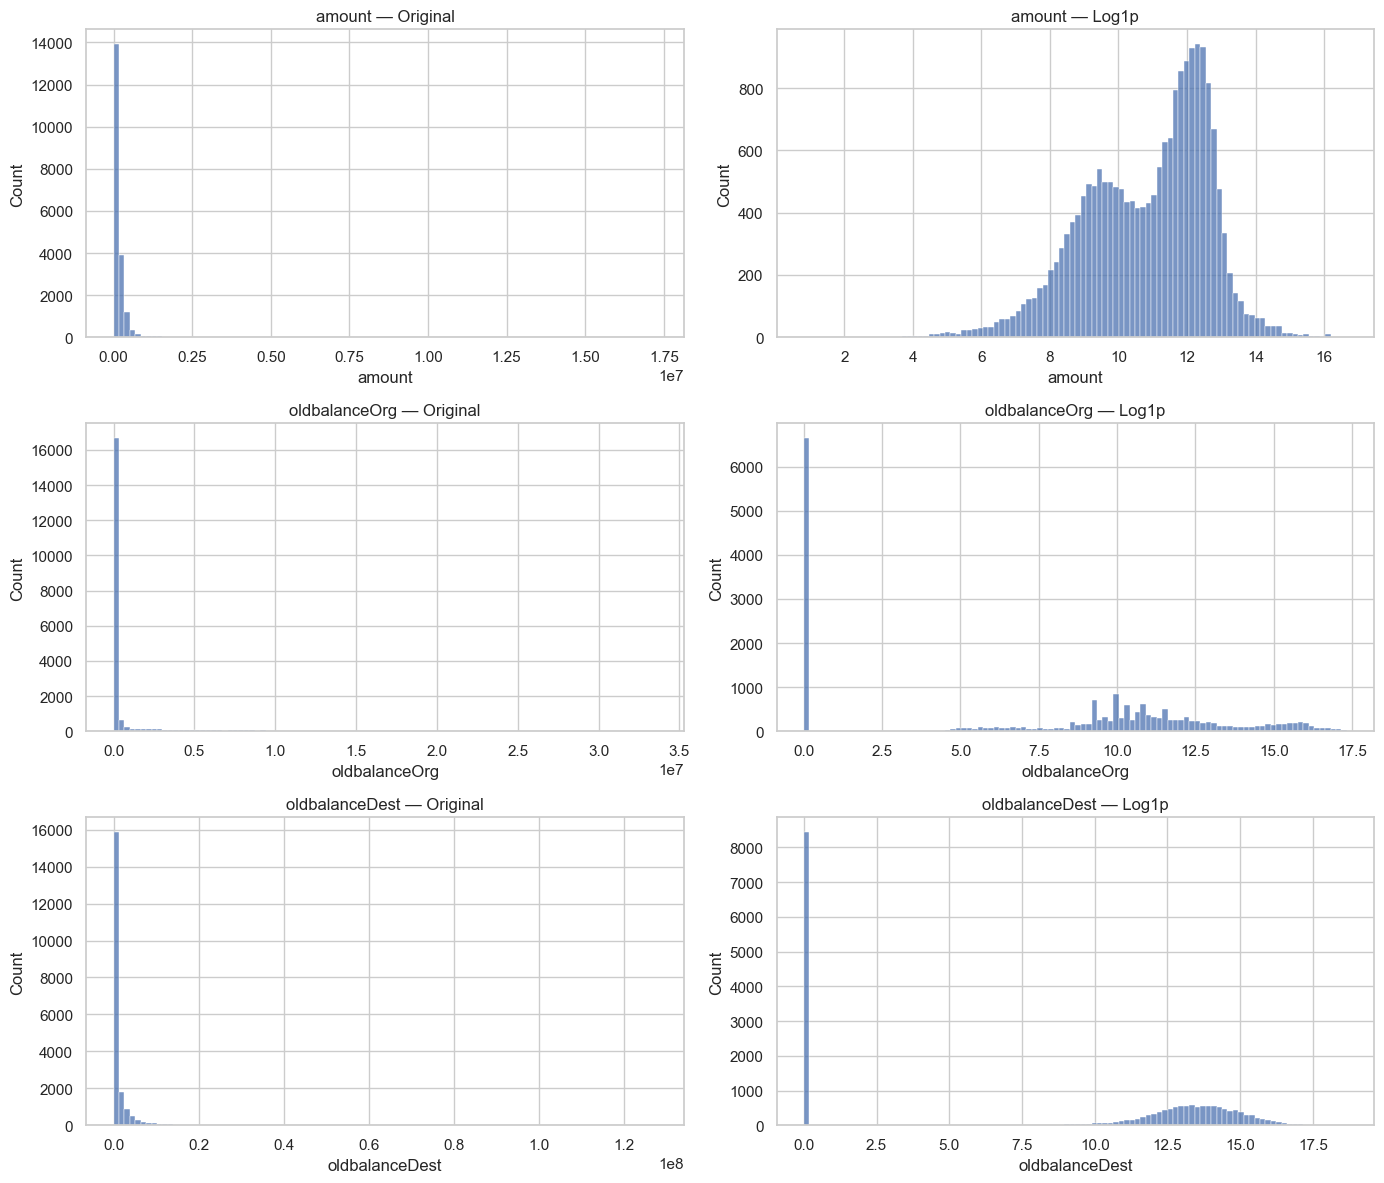

In [43]:
log_features = [
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

fig, axes = plt.subplots(
    len(log_features), 2,
    figsize=(14, 12)
)

for i, column in enumerate(log_features):

    # Original distribution
    sns.histplot(
        df_clean[column].sample(
            n=20000,
            random_state=RANDOM_STATE
        ),
        bins=100,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"{column} — Original")

    # Log-transformed distribution
    sns.histplot(
        np.log1p(
            df_clean[column].sample(
                n=20000,
                random_state=RANDOM_STATE
            )
        ),
        bins=100,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"{column} — Log1p")

plt.tight_layout()
plt.show()

In [44]:
assert (df_clean[log_features] >= 0).all().all(), (
    "Negative values found. Investigate before applying log1p."
)

### 6.1 Train, Validation, and Test Split

The dataset is divided into three independent subsets.

- Training set: model fitting and preprocessing fitting.
- Validation set: model comparison and threshold optimization.
- Test set: final evaluation only.

Stratified sampling is used to preserve the target class distribution.

The test set will remain untouched until final evaluation.

In [46]:
FEATURES = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

TARGET = "isFraud"

X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

indices = np.arange(len(df_clean))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y.iloc[temp_idx]
)

# Create partitions
X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

X shape: (6362620, 5)
y shape: (6362620,)
Training: (4453834, 5) (4453834,)
Validation: (954393, 5) (954393,)
Testing: (954393, 5) (954393,)


In [47]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nFraud distribution:")

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts())
    print("Fraud percentage:", round(target.mean() * 100, 4), "%")

Training set: (4453834, 5)
Validation set: (954393, 5)
Testing set: (954393, 5)

Fraud distribution:

Training:
isFraud
0    4448085
1       5749
Name: count, dtype: int64
Fraud percentage: 0.1291 %

Validation:
isFraud
0    953161
1      1232
Name: count, dtype: int64
Fraud percentage: 0.1291 %

Testing:
isFraud
0    953161
1      1232
Name: count, dtype: int64
Fraud percentage: 0.1291 %


### 7.1 Logistic Regression Pipeline

A complete pipeline combines preprocessing and model training.

All preprocessing transformations are fitted only on the training
data to prevent data leakage.

Class weighting is used to compensate for the severe class imbalance.

In [50]:

# Separate preprocessing branches
step_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

financial_pipeline = Pipeline([
    ("log_transform", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("step", step_pipeline, ["step"]),
    ("financial", financial_pipeline, [
        "amount",
        "oldbalanceOrg",
        "oldbalanceDest"
    ]),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ))
])

In [51]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Generate class predictions
y_val_pred = logistic_pipeline.predict(X_val)

# Generate fraud probabilities
y_val_proba = logistic_pipeline.predict_proba(X_val)[:, 1]

print("Predictions generated successfully.")
print("Predictions shape:", y_val_pred.shape)
print("Probabilities shape:", y_val_proba.shape)

results = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred),
    "Average Precision (PR-AUC)": average_precision_score(
        y_val, y_val_proba
    )
}

for metric, value in results.items():
    print(f"{metric}: {value:.6f}")

Predictions generated successfully.
Predictions shape: (954393,)
Probabilities shape: (954393,)
Accuracy: 0.906609
Precision: 0.013408
Recall: 0.982955
F1-score: 0.026454
Balanced Accuracy: 0.944732
Average Precision (PR-AUC): 0.055453


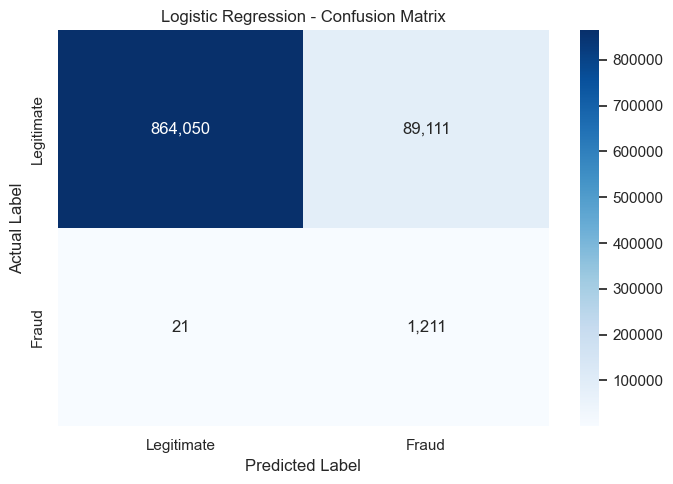

In [56]:


cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [57]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      0.91      0.95    953161
       Fraud       0.01      0.98      0.03      1232

    accuracy                           0.91    954393
   macro avg       0.51      0.94      0.49    954393
weighted avg       1.00      0.91      0.95    954393



In [58]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

tn, fp, fn, tp = cm.ravel()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

print("\nFraud Detection Analysis:")
print("Fraud detected:", tp)
print("Fraud missed:", fn)
print("Legitimate transactions incorrectly flagged:", fp)

print(
    "False Positive Rate:",
    round(fp / (fp + tn) * 100, 4),
    "%"
)

print(
    "Fraud Alert Precision:",
    round(tp / (tp + fp) * 100, 4),
    "%"
)

True Negatives (TN): 864050
False Positives (FP): 89111
False Negatives (FN): 21
True Positives (TP): 1211

Fraud Detection Analysis:
Fraud detected: 1211
Fraud missed: 21
Legitimate transactions incorrectly flagged: 89111
False Positive Rate: 9.349 %
Fraud Alert Precision: 1.3408 %


#### 7.2 Logistic Regression - Business Analysis

The Logistic Regression model achieved a fraud recall of 98.30%,
successfully identifying 1,211 out of 1,232 fraudulent transactions.

However, it generated 89,111 false positives, resulting in a
precision of only 1.34%.

Although the model minimizes missed fraudulent transactions,
its high false-positive volume could create significant operational
costs and unnecessary transaction reviews.

The model demonstrates the importance of balancing fraud detection
performance with false-alarm reduction.

Further experiments will investigate alternative classifiers,
class imbalance strategies, and decision threshold optimization.


### 8.1 Decision Tree Classifier

Decision Trees learn decision rules by splitting the feature space
into smaller regions.

They can capture nonlinear relationships and interactions between
transaction features.

Unlike Logistic Regression, Decision Trees do not require feature
scaling.

We use class weighting to address the severe class imbalance.

In [60]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Categorical preprocessing
categorical_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["type"]
        )
    ],
    remainder="passthrough"
)

# Complete Decision Tree pipeline
decision_tree_pipeline = Pipeline([
    ("preprocessor", categorical_preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=RANDOM_STATE
    ))
])

# Train
decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [61]:
y_val_pred_dt = decision_tree_pipeline.predict(X_val)

y_val_proba_dt = decision_tree_pipeline.predict_proba(X_val)[:, 1]

print("Decision Tree predictions completed.")

Decision Tree predictions completed.


In [62]:
dt_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_dt),
    "Precision": precision_score(
        y_val, y_val_pred_dt, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_dt, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_dt, zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_val_pred_dt
    ),
    "Average Precision (PR-AUC)": average_precision_score(
        y_val, y_val_proba_dt
    )
}

for metric, value in dt_results.items():
    print(f"{metric}: {value:.6f}")

Accuracy: 0.972780
Precision: 0.044539
Recall: 0.982143
F1-score: 0.085214
Balanced Accuracy: 0.977455
Average Precision (PR-AUC): 0.733910


In [63]:
cm_dt = confusion_matrix(y_val, y_val_pred_dt)

tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()

print("True Negatives:", tn_dt)
print("False Positives:", fp_dt)
print("False Negatives:", fn_dt)
print("True Positives:", tp_dt)

print("\nFraud Detection Analysis:")
print("Fraud detected:", tp_dt)
print("Fraud missed:", fn_dt)
print("False fraud alerts:", fp_dt)

print(
    "False Positive Rate:",
    round(fp_dt / (fp_dt + tn_dt) * 100, 4),
    "%"
)

True Negatives: 927204
False Positives: 25957
False Negatives: 22
True Positives: 1210

Fraud Detection Analysis:
Fraud detected: 1210
Fraud missed: 22
False fraud alerts: 25957
False Positive Rate: 2.7233 %


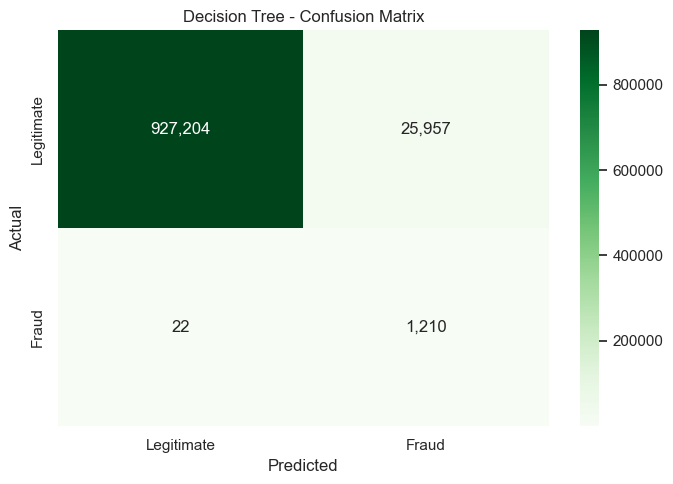

In [64]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt=",",
    cmap="Greens",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#### 8.2 Decision Tree - Evaluation and Business Analysis

The Decision Tree achieved an Average Precision score of 0.7339
and a fraud recall of 98.21%.

Its confusion matrix shows:

- True Negatives: 927,204
- False Positives: 25,957
- False Negatives: 22
- True Positives: 1,210

Compared with Logistic Regression, the Decision Tree reduced
false positives by approximately 70.9% while maintaining
a similar fraud detection rate.

This suggests that nonlinear decision boundaries provide
a substantial advantage for this dataset.

However, the model still generates a considerable number
of false alerts, requiring further optimization.

### 9.1 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines
multiple decision trees to improve predictive performance.

It uses bootstrap sampling and random feature selection to
reduce overfitting and improve generalization.

The model uses balanced class weights to address the severe
imbalance between legitimate and fraudulent transactions.

No numerical scaling is required, but categorical features
must be encoded.

In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            ["type"]
        )
    ],
    remainder="passthrough"
)

random_forest_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

In [66]:
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully.")    

Random Forest trained successfully.


In [67]:
y_val_pred_rf = random_forest_pipeline.predict(X_val)

y_val_proba_rf = random_forest_pipeline.predict_proba(X_val)[:, 1]

rf_results = {
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_pred_rf, zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_val_pred_rf
    ),
    "Average Precision (PR-AUC)": average_precision_score(
        y_val, y_val_proba_rf
    )
}

for metric, value in rf_results.items():
    print(f"{metric}: {value:.6f}")

Accuracy: 0.985085
Precision: 0.077797
Recall: 0.972403
F1-score: 0.144068
Balanced Accuracy: 0.978752
Average Precision (PR-AUC): 0.838804


In [68]:
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()

print("True Negatives:", tn_rf)
print("False Positives:", fp_rf)
print("False Negatives:", fn_rf)
print("True Positives:", tp_rf)

print("\nFraud Detection Analysis:")
print("Fraud detected:", tp_rf)
print("Fraud missed:", fn_rf)
print("False fraud alerts:", fp_rf)

print(
    "False Positive Rate:",
    round(fp_rf / (fp_rf + tn_rf) * 100, 4),
    "%"
)

True Negatives: 938960
False Positives: 14201
False Negatives: 34
True Positives: 1198

Fraud Detection Analysis:
Fraud detected: 1198
Fraud missed: 34
False fraud alerts: 14201
False Positive Rate: 1.4899 %


In [69]:
model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", **results},
    {"Model": "Decision Tree", **dt_results},
    {"Model": "Random Forest", **rf_results}
])

model_comparison = model_comparison.set_index("Model")

model_comparison.sort_values(
    by="Average Precision (PR-AUC)",
    ascending=False
)

,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision (PR-AUC)
Model,,,,,,
Random Forest,0.9851,0.0778,0.9724,0.1441,0.9788,0.8388
Decision Tree,0.9728,0.0445,0.9821,0.0852,0.9775,0.7339
Logistic Regression,0.9066,0.0134,0.9830,0.0265,0.9447,0.0555


#### 9.2 Random Forest - Evaluation and Business Analysis

The Random Forest classifier achieved an Average Precision score
of 0.8388 and a fraud recall of 97.24%.

Confusion matrix:

- True Negatives: 938,960
- False Positives: 14,201
- False Negatives: 34
- True Positives: 1,198

Compared with the Decision Tree, Random Forest reduced false
positives by approximately 45.3%, while maintaining a high
fraud detection rate.

It currently provides the strongest overall performance among
the evaluated models.

However, further optimization is required to reduce false
alerts without significantly increasing missed fraud cases.

In [70]:
from pathlib import Path
import joblib

# Create the models directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Model artifact path
MODEL_PATH = MODEL_DIR / "fraud_detection_pipeline.joblib"

# Deployment configuration
model_bundle = {
    "model": random_forest_pipeline,
    "features": FEATURES,
    "target": TARGET,
    "threshold": 0.5,
    "model_name": "Random Forest"
}

# Export
joblib.dump(model_bundle, MODEL_PATH)

print(f"Model saved successfully: {MODEL_PATH.resolve()}")

Model saved successfully: E:\source\ml projects\mobile_wallet_fraud_detection\models\fraud_detection_pipeline.joblib


In [71]:
loaded_bundle = joblib.load(MODEL_PATH)

loaded_model = loaded_bundle["model"]

print("Model:", loaded_bundle["model_name"])
print("Features:", loaded_bundle["features"])
print("Threshold:", loaded_bundle["threshold"])

print("\nModel artifact loaded successfully.")

Model: Random Forest
Features: ['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']
Threshold: 0.5

Model artifact loaded successfully.
